In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Database Connection
conn=sqlite3.connect("../inventory.db")
df=pd.read_sql_query("select * from vendor_sales_summary",conn)
df.head()

,VendorNumber,VendorName,Brand,Description,total_pur_qty,total_pur_dollars,avg_retail_price,avg_purchase_price,TotalSalesQuantity,TotalSalesDollars,TotalFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",90085,Ch Lilian 09 Ladouys St Este,8,190.88,36.99,23.86,18.0,665.82,27.08,474.94,71.331591,2.250000,3.488160
1,2,"IRA GOLDMAN AND WILLIAMS, LLP",90609,Flavor Essence Variety 5 Pak,320,5440.00,24.99,17.00,24.0,599.76,27.08,-4840.24,-807.029478,0.075000,0.110250
2,54,AAPER ALCOHOL & CHEMICAL CO,990,Ethyl Alcohol 200 Proof,1,105.07,134.49,105.07,0.0,0.00,0.48,-105.07,0.000000,0.000000,0.000000
3,60,ADAMBA IMPORTS INTL INC,771,Bak's Krupnik Honey Liqueur,39,446.16,14.99,11.44,47.0,704.53,367.52,258.37,36.672675,1.205128,1.579097
4,60,ADAMBA IMPORTS INTL INC,3401,Vesica Vodka,6,66.60,14.99,11.10,0.0,0.00,367.52,-66.60,0.000000,0.000000,0.000000


In [2]:
# No of rows:
df.shape

(12490, 15)

In [3]:
# Column Names and Data Types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12490 entries, 0 to 12489
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   VendorNumber          12490 non-null  int64  
 1   VendorName            12490 non-null  object 
 2   Brand                 12490 non-null  int64  
 3   Description           12490 non-null  object 
 4   total_pur_qty         12490 non-null  int64  
 5   total_pur_dollars     12490 non-null  float64
 6   avg_retail_price      12490 non-null  float64
 7   avg_purchase_price    12490 non-null  float64
 8   TotalSalesQuantity    12490 non-null  float64
 9   TotalSalesDollars     12490 non-null  float64
 10  TotalFreight          12490 non-null  float64
 11  GrossProfit           12490 non-null  float64
 12  ProfitMargin          12490 non-null  float64
 13  StockTurnover         12490 non-null  float64
 14  SalesToPurchaseRatio  12490 non-null  float64
dtypes: float64(10), int

In [4]:
# Statistical Summary
df.describe()

,VendorNumber,Brand,total_pur_qty,total_pur_dollars,avg_retail_price,avg_purchase_price,TotalSalesQuantity,TotalSalesDollars,TotalFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
count,12490.000000,12490.000000,12490.000000,1.249000e+04,12490.000000,12490.000000,12490.000000,1.249000e+04,12490.000000,1.249000e+04,12490.000000,12490.000000,12490.000000
mean,9672.429384,18846.225540,2946.673579,2.839953e+04,36.598260,24.890224,2886.434027,4.005364e+04,52590.828725,1.165411e+04,-20.345609,1.746455,2.573212
std,17518.905848,12525.370437,10618.231918,1.203296e+05,141.232611,103.578313,10480.890016,1.635569e+05,60307.409157,4.495640e+04,496.747277,5.984619,8.466009
min,2.000000,58.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.090000,-5.200278e+04,-23730.638953,0.000000,0.000000
25%,3960.000000,6918.250000,36.000000,4.719150e+02,10.990000,7.140000,32.000000,7.821300e+02,6015.860000,5.379750e+01,13.238585,0.805556,1.151802
50%,4425.000000,19690.000000,240.000000,3.545640e+03,16.990000,10.800000,238.000000,5.125495e+03,28720.520000,1.430810e+03,30.965549,0.981072,1.448535
75%,9552.000000,25825.250000,1805.000000,1.922606e+04,29.990000,20.422500,1736.750000,2.650512e+04,68601.680000,8.165645e+03,40.630861,1.046344,1.684270
max,201359.000000,90631.000000,337660.000000,3.811252e+06,7499.990000,5681.810000,334939.000000,5.101920e+06,257032.070000,1.290668e+06,100.000000,274.500000,352.928571


In [5]:
df.isnull().sum()

VendorNumber            0
VendorName              0
Brand                   0
Description             0
total_pur_qty           0
total_pur_dollars       0
avg_retail_price        0
avg_purchase_price      0
TotalSalesQuantity      0
TotalSalesDollars       0
TotalFreight            0
GrossProfit             0
ProfitMargin            0
StockTurnover           0
SalesToPurchaseRatio    0
dtype: int64

In [7]:
# Checking Negative Gross Profit
negative_profit=df[df["GrossProfit"]<0]
print("Negative Gross Profit Records: ",negative_profit.shape[0] )
negative_profit.head()

Negative Gross Profit Records:  2514


,VendorNumber,VendorName,Brand,Description,total_pur_qty,total_pur_dollars,avg_retail_price,avg_purchase_price,TotalSalesQuantity,TotalSalesDollars,TotalFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
1,2,"IRA GOLDMAN AND WILLIAMS, LLP",90609,Flavor Essence Variety 5 Pak,320,5440.00,24.99,17.00,24.0,599.76,27.08,-4840.24,-807.029478,0.075000,0.110250
2,54,AAPER ALCOHOL & CHEMICAL CO,990,Ethyl Alcohol 200 Proof,1,105.07,134.49,105.07,0.0,0.00,0.48,-105.07,0.000000,0.000000,0.000000
4,60,ADAMBA IMPORTS INTL INC,3401,Vesica Vodka,6,66.60,14.99,11.10,0.0,0.00,367.52,-66.60,0.000000,0.000000,0.000000
5,60,ADAMBA IMPORTS INTL INC,3979,Vesica Potato Vodka,4687,76257.49,20.99,16.27,3931.0,66871.69,367.52,-9385.80,-14.035536,0.838703,0.876920
8,200,AMERICAN SPIRITS EXCHANGE,19715,Slices Sangria Red,36,271.08,10.99,7.53,19.0,208.81,6.19,-62.27,-29.821369,0.527778,0.770289


In [9]:
# Zero Sales and Zero Purchases 
zero_sales=df[df["TotalSalesDollars"]==0]
zero_pur=df[df["total_pur_dollars"]==0]

print("\n Zero Sales reocrds: ",zero_sales.shape[0] )
print("\n Zero Purchase records: ",zero_pur.shape[0])

zero_sales.head()
zero_pur.head()


 Zero Sales reocrds:  209

 Zero Purchase records:  1


,VendorNumber,VendorName,Brand,Description,total_pur_qty,total_pur_dollars,avg_retail_price,avg_purchase_price,TotalSalesQuantity,TotalSalesDollars,TotalFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
2377,2561,EDRINGTON AMERICAS,2166,The Macallan Double Cask 12,2015,0.0,0.0,0.0,1732.0,98245.68,9654.5,98245.68,100.0,0.859553,0.0


In [12]:
negative_turnover = df[df["StockTurnover"] < 0]

low_turnover = df[df["StockTurnover"] < 0.5]

print("Negative Turnover Records:", negative_turnover.shape[0])
print("Turnover Below 0.5:", low_turnover.shape[0])

Negative Turnover Records: 0
Turnover Below 0.5: 1539


In [18]:
# Outliers in purchase,sales,freight

columns_to_check=[
    "total_pur_dollars",
    "TotalSalesDollars",
    "TotalFreight"
]
for col in columns_to_check:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)

    IQR=q3-q1

    lower_limit=q1-1.5*IQR
    upper_limit=q3+1.5*IQR

    outliers=df[
        (df[col]<lower_limit) |
        (df[col]>upper_limit)
    ]
    print(f"{col}: {outliers.shape[0]} outliers")

total_pur_dollars: 1600 outliers
TotalSalesDollars: 1633 outliers
TotalFreight: 396 outliers


In [30]:
# Correlation heatmap
correlation = df.corr(numeric_only=True)
correlation

,VendorNumber,Brand,total_pur_qty,total_pur_dollars,avg_retail_price,avg_purchase_price,TotalSalesQuantity,TotalSalesDollars,TotalFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
VendorNumber,1.000000,0.045407,-0.049736,-0.039430,-0.020438,-0.019871,-0.050080,-0.042493,-0.162132,-0.049058,-0.006467,-0.012062,-0.011541
Brand,0.045407,1.000000,-0.140027,-0.146202,-0.038406,-0.049612,-0.139552,-0.139520,-0.195765,-0.116269,-0.022861,-0.025285,-0.013631
total_pur_qty,-0.049736,-0.140027,1.000000,0.687178,-0.044268,-0.040868,0.998695,0.701195,0.163126,0.711744,0.025098,-0.035564,-0.036878
total_pur_dollars,-0.039430,-0.146202,0.687178,1.000000,-0.014488,-0.011830,0.685172,0.996126,0.143953,0.947444,0.017622,-0.030526,-0.032428
avg_retail_price,-0.020438,-0.038406,-0.044268,-0.014488,1.000000,0.997054,-0.044097,-0.017745,0.013478,-0.025780,-0.009838,-0.001421,-0.002058
avg_purchase_price,-0.019871,-0.049612,-0.040868,-0.011830,0.997054,1.000000,-0.040743,-0.015343,0.017459,-0.024155,-0.009831,-0.002195,-0.003170
TotalSalesQuantity,-0.050080,-0.139552,0.998695,0.685172,-0.044097,-0.040743,1.000000,0.700691,0.163818,0.715280,0.027817,-0.030838,-0.032220
TotalSalesDollars,-0.042493,-0.139520,0.701195,0.996126,-0.017745,-0.015343,0.700691,1.000000,0.142223,0.971906,0.024409,-0.028191,-0.029571
TotalFreight,-0.162132,-0.195765,0.163126,0.143953,0.013478,0.017459,0.163818,0.142223,1.000000,0.132122,0.019191,0.003840,0.000345
GrossProfit,-0.049058,-0.116269,0.711744,0.947444,-0.025780,-0.024155,0.715280,0.971906,0.132122,1.000000,0.041634,-0.020857,-0.020788


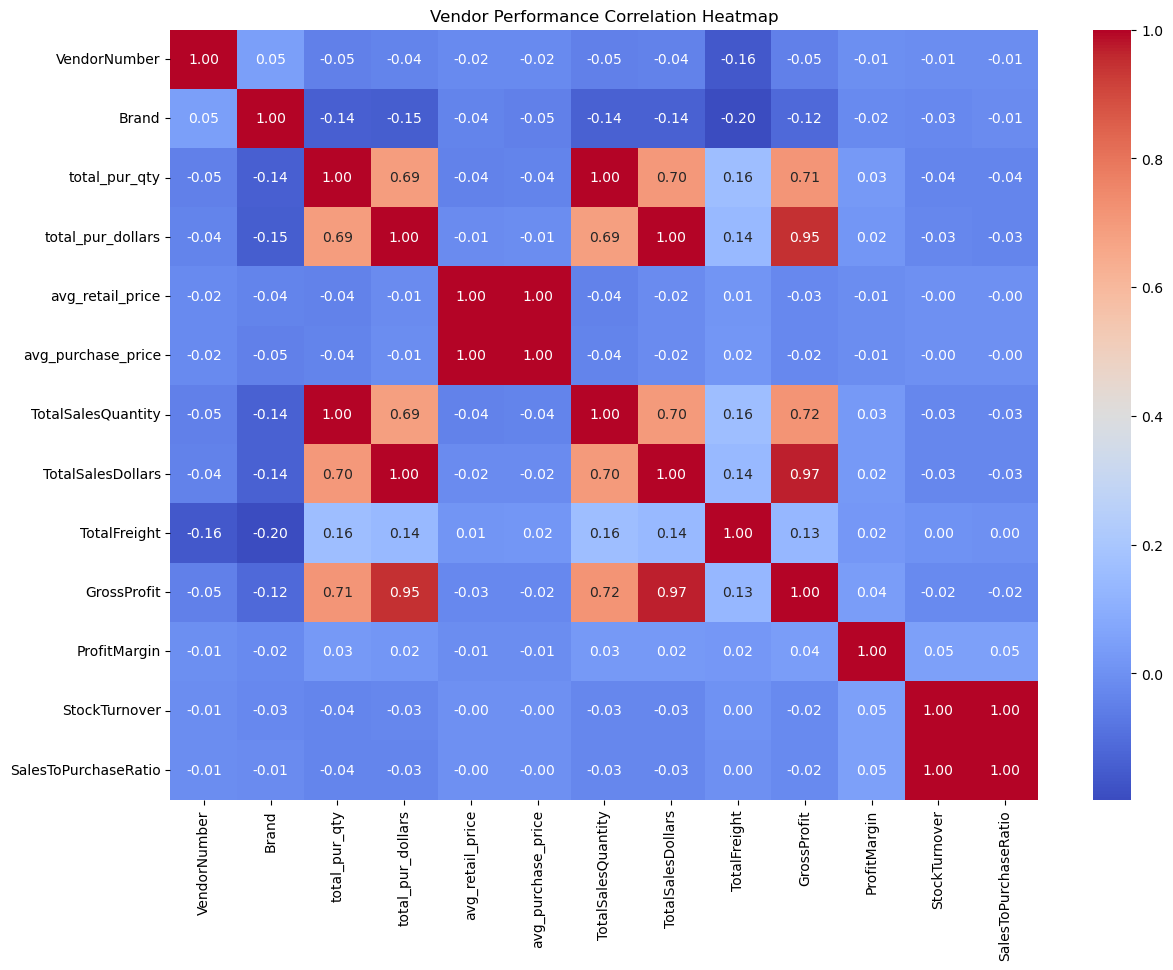

In [31]:
# Correlation Heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Vendor Performance Correlation Heatmap")
plt.show()

In [32]:
# Brand & Product Performance Analysis
#Which products generate the highest sales?

top_products = df.sort_values(
    by="TotalSalesDollars",
    ascending=False
).head(10)

top_products[
    ["Description", "Brand", "VendorName", "TotalSalesDollars"]
]

,Description,Brand,VendorName,TotalSalesDollars
636,Jack Daniels No 7 Black,1233,BROWN-FORMAN CORP,5101919.51
3645,Tito's Handmade Vodka,3405,MARTIGNETTI COMPANIES,4819073.49
3646,Tito's Handmade Vodka,3405,MARTIGNETTI COMPANIES,4819073.49
11865,Absolut 80 Proof,8068,PERNOD RICARD USA,4538120.60
3385,Capt Morgan Spiced Rum,4261,DIAGEO NORTH AMERICA INC,4475972.88
3317,Ketel One Vodka,3545,DIAGEO NORTH AMERICA INC,4223107.62
86,Grey Goose Vodka,3858,BACARDI USA INC,3383912.40
11766,Jameson Irish Whiskey,2589,PERNOD RICARD USA,2773367.73
3308,Tanqueray,3489,DIAGEO NORTH AMERICA INC,2640491.19
3271,Smirnoff Traveler,3102,DIAGEO NORTH AMERICA INC,2592041.35


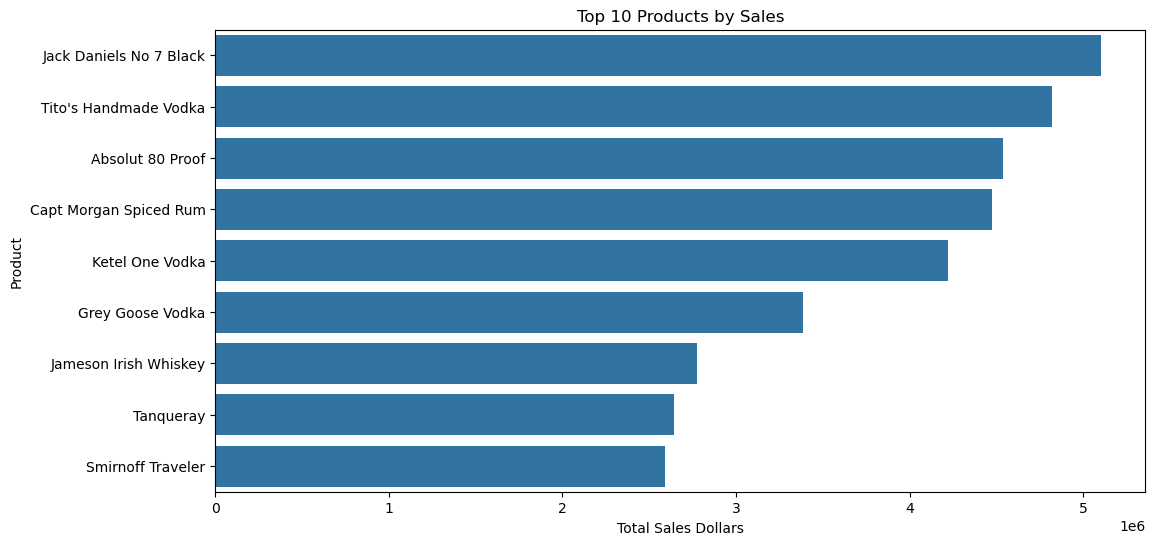

In [33]:
# Visualize Top 10 Products
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="TotalSalesDollars",
    y="Description"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales Dollars")
plt.ylabel("Product")

plt.show()

In [34]:
# Product with high profit margin
hight_profit_margin=df.sort_values(by="ProfitMargin",ascending=False).head(10)
hight_profit_margin[["Description","Brand","VendorName","TotalSalesDollars","GrossProfit","ProfitMargin"]]

,Description,Brand,VendorName,TotalSalesDollars,GrossProfit,ProfitMargin
2377,The Macallan Double Cask 12,2166,EDRINGTON AMERICAS,98245.68,98245.68,100.000000
6636,Blue Chair Bay Coconut Rum,4703,MHW LTD,2717.55,2709.85,99.716657
8517,Pezzi King Svgn Bl Dry Creek,11209,ULTRA BEVERAGE COMPANY LLP,2221.29,2212.51,99.604734
2370,DiSaronno Amaretto,5831,DISARONNO INTERNATIONAL LLC,4781.16,4759.80,99.553246
11506,Skinnygirl Tangerine Vodka,3406,JIM BEAM BRANDS COMPANY,2368.42,2357.64,99.544844
10462,Beniotome Sesame Shochu,5335,PERFECTA WINES,4768.41,4746.20,99.534226
6461,M Chiarlo Gavi Wh,40583,KOBRAND CORPORATION,1208.90,1201.57,99.393664
7157,Ch La Croix Lartigue 09,23948,PINE STATE TRADING CO,3937.99,3912.84,99.361349
9410,Rhone Roger Sabon 13 CDR Rou,19526,M S WALKER INC,1440.97,1431.58,99.348356
5053,L'Enclos de Viaud Lalande Po,25018,MARTIGNETTI COMPANIES,3148.95,3128.27,99.343273


In [35]:
# Product with Negative Gross Profit
loss_products=df[df["GrossProfit"]<0].sort_values(by="GrossProfit",ascending=True).head(10)
loss_products[["Description","Brand","VendorName","TotalSalesDollars","GrossProfit"]]

,Description,Brand,VendorName,TotalSalesDollars,GrossProfit
11440,Kilbeggan Irish Whiskey,2277,JIM BEAM BRANDS COMPANY,20272.54,-52002.78
7320,Remy Martin XO Excellence,4785,REMY COINTREAU USA INC,21237.26,-38161.69
10443,Whistle Pig Boss Hog Rye,2289,PERFECTA WINES,11062.63,-33426.71
9220,Integre Vodka,5609,M S WALKER INC,2575.70,-30984.58
10423,Russian Standard Vodka,3365,Russian Standard Vodka,12569.97,-29280.63
8466,Westland Trinity 3 Pack,6904,ULTRA BEVERAGE COMPANY LLP,6149.18,-29150.98
1716,San Polo Brun di Montlcno 11,15880,SOUTHERN WINE & SPIRITS NE,149.98,-29064.02
1715,San Polo Brun di Montlcno 11,15880,SOUTHERN WINE & SPIRITS NE,149.98,-29064.02
2051,High Valley Znfdl,25588,SOUTHERN WINE & SPIRITS NE,55406.43,-24802.91
2052,High Valley Znfdl,25588,SOUTHERN WINE & SPIRITS NE,55406.43,-24802.91


In [46]:
#Vendor Sales Performance Analysis
# Which vendors generate the highest total sales?
top_vendors=df.groupby(["VendorNumber","VendorName"])["TotalSalesDollars"].sum().reset_index()
top_vendors=top_vendors.sort_values(by="TotalSalesDollars",ascending=False).head(10)
top_vendors

,VendorNumber,VendorName,TotalSalesDollars
44,4425,MARTIGNETTI COMPANIES,81920235.64
42,3960,DIAGEO NORTH AMERICA INC,68739834.97
101,17035,PERNOD RICARD USA,32279544.17
97,12546,JIM BEAM BRANDS COMPANY,31898621.16
7,480,BACARDI USA INC,25005365.79
16,1392,CONSTELLATION BRANDS INC,24467134.23
36,3252,E & J GALLO WINERY,18553774.66
12,1128,BROWN-FORMAN CORP,18476611.60
82,9165,ULTRA BEVERAGE COMPANY LLP,17802646.10
85,9552,M S WALKER INC,15436066.26


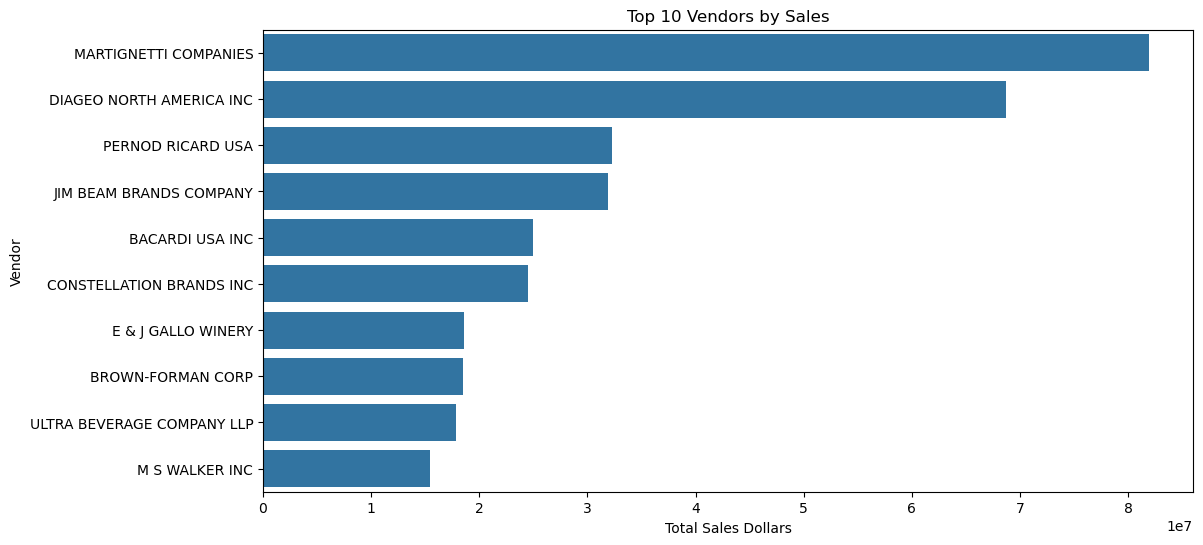

In [47]:
# Visulising Top 10 Vendors
plt.figure(figsize=(12,6))
sns.barplot(
    data=top_vendors,
    x="TotalSalesDollars",
    y="VendorName"
)
plt.title("Top 10 Vendors by Sales")
plt.xlabel("Total Sales Dollars")
plt.ylabel("Vendor")
plt.show()

In [49]:
# What percentage of total sales does each vendor contribute?
vendor_sales=df.groupby("VendorName")["TotalSalesDollars"].sum().reset_index()
vendor_sales["SalesContribution"]=(vendor_sales["TotalSalesDollars"]/vendor_sales["TotalSalesDollars"].sum())*100
vendor_sales=vendor_sales.sort_values(by="SalesContribution",ascending=False)
vendor_sales.head(10)

,VendorName,TotalSalesDollars,SalesContribution
63,MARTIGNETTI COMPANIES,81920235.64,16.375204
28,DIAGEO NORTH AMERICA INC,68739834.97,13.740546
74,PERNOD RICARD USA,32279544.17,6.452424
50,JIM BEAM BRANDS COMPANY,31898621.16,6.376281
8,BACARDI USA INC,25005365.79,4.998374
23,CONSTELLATION BRANDS INC,24467134.23,4.890786
33,E & J GALLO WINERY,18553774.66,3.708752
14,BROWN-FORMAN CORP,18476611.60,3.693328
114,ULTRA BEVERAGE COMPANY LLP,17802646.10,3.558607
59,M S WALKER INC,15436066.26,3.085547


In [50]:
top10_contribution = vendor_sales.head(10)["SalesContribution"].sum()

print("Top 10 Vendors Sales Contribution:", round(top10_contribution, 2), "%")

Top 10 Vendors Sales Contribution: 66.88 %


In [58]:
# Which vendors receive the highest purchasing expenditure?
pur_exp=df.groupby(["VendorNumber","VendorName"])["total_pur_dollars"].sum()
pur_exp=pur_exp.sort_values(ascending=False).head(10)
pur_exp

VendorNumber  VendorName                
4425          MARTIGNETTI COMPANIES         55723380.04
3960          DIAGEO NORTH AMERICA INC      50959796.85
12546         JIM BEAM BRANDS COMPANY       24203151.05
17035         PERNOD RICARD USA             24124091.56
480           BACARDI USA INC               17624378.72
1392          CONSTELLATION BRANDS INC      15573917.90
1128          BROWN-FORMAN CORP             13529433.08
9165          ULTRA BEVERAGE COMPANY LLP    13210613.93
3252          E & J GALLO WINERY            12289608.09
9552          M S WALKER INC                10935817.30
Name: total_pur_dollars, dtype: float64

In [63]:
# What percentage of total purchasing expenditure does each vendor represent?
pur_contribution=(pur_exp/pur_exp.sum()*100).round(2)
pur_contribution.head(10)

VendorName
MARTIGNETTI COMPANIES         15.71
DIAGEO NORTH AMERICA INC      14.37
JIM BEAM BRANDS COMPANY        6.82
PERNOD RICARD USA              6.80
BACARDI USA INC                4.97
CONSTELLATION BRANDS INC       4.39
BROWN-FORMAN CORP              3.81
ULTRA BEVERAGE COMPANY LLP     3.72
E & J GALLO WINERY             3.46
M S WALKER INC                 3.08
Name: total_pur_dollars, dtype: float64

In [64]:
#How much of total purchasing expenditure is contributed cumulatively by our top vendors?

pur_pareto=pur_contribution.reset_index()
pur_pareto["CumulativeContribution"]=(pur_pareto["total_pur_dollars"].cumsum().round(2))
pur_pareto.head(10)

,VendorName,total_pur_dollars,CumulativeContribution
0,MARTIGNETTI COMPANIES,15.71,15.71
1,DIAGEO NORTH AMERICA INC,14.37,30.08
2,JIM BEAM BRANDS COMPANY,6.82,36.90
3,PERNOD RICARD USA,6.80,43.70
4,BACARDI USA INC,4.97,48.67
5,CONSTELLATION BRANDS INC,4.39,53.06
6,BROWN-FORMAN CORP,3.81,56.87
7,ULTRA BEVERAGE COMPANY LLP,3.72,60.59
8,E & J GALLO WINERY,3.46,64.05
9,M S WALKER INC,3.08,67.13


In [67]:
# Do we receive lower purchase prices when purchasing larger quantities?

#Calculate Unit Purchase Price
df["UnitPurchasePrice"] = (
    df["total_pur_dollars"] / df["total_pur_qty"]
)

#Create Purchase Quantity Categories
df["PurchaseQuantityCategory"] = pd.qcut(
    df["total_pur_qty"],
    q=3,
    labels=["Small", "Medium", "Large"]
)

#Compare Unit Purchase Prices
df.groupby(
    "PurchaseQuantityCategory",
    observed=True
)["UnitPurchasePrice"].mean()


PurchaseQuantityCategory
Small     44.664666
Medium    18.082462
Large     11.467024
Name: UnitPurchasePrice, dtype: float64

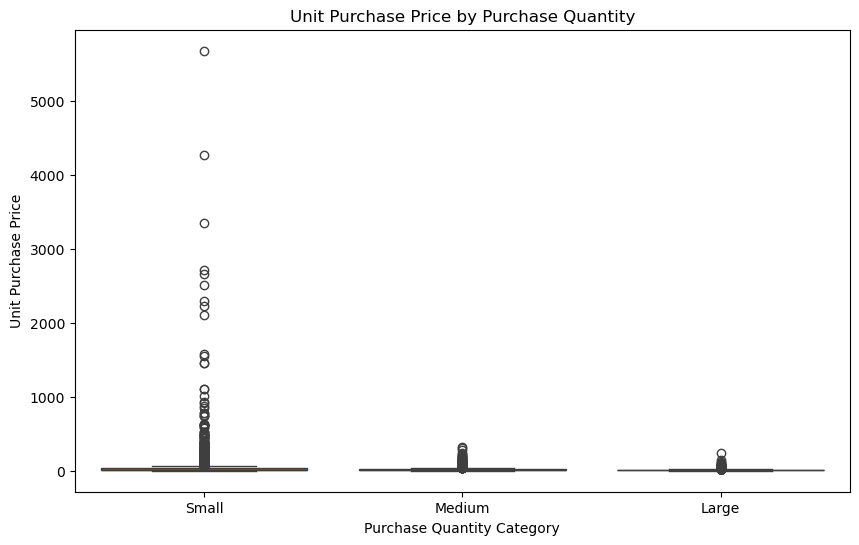

In [68]:
#Visualize Purchase Price by Quantity
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="PurchaseQuantityCategory",
    y="UnitPurchasePrice"
)

plt.title("Unit Purchase Price by Purchase Quantity")
plt.xlabel("Purchase Quantity Category")
plt.ylabel("Unit Purchase Price")

plt.show()

In [72]:
slow_moving=df[df["StockTurnover"]<1]
slow_moving=slow_moving.sort_values(by="total_pur_dollars",ascending=False)

slow_moving[[
    "VendorName",
    "Description",
    "total_pur_qty",
    "TotalSalesQuantity",
    "StockTurnover",
    "total_pur_dollars"
]].head(10)

,VendorName,Description,total_pur_qty,TotalSalesQuantity,StockTurnover,total_pur_dollars
636,BROWN-FORMAN CORP,Jack Daniels No 7 Black,145080,142049.0,0.979108,3811251.60
3646,MARTIGNETTI COMPANIES,Tito's Handmade Vodka,164038,160247.0,0.976890,3804041.22
3645,MARTIGNETTI COMPANIES,Tito's Handmade Vodka,164038,160247.0,0.976890,3804041.22
11865,PERNOD RICARD USA,Absolut 80 Proof,187407,187140.0,0.998575,3418303.68
3385,DIAGEO NORTH AMERICA INC,Capt Morgan Spiced Rum,201682,200412.0,0.993703,3261197.94
3317,DIAGEO NORTH AMERICA INC,Ketel One Vodka,138109,135838.0,0.983556,3023206.01
11766,PERNOD RICARD USA,Jameson Irish Whiskey,70783,69627.0,0.983668,2177285.08
3271,DIAGEO NORTH AMERICA INC,Smirnoff Traveler,161386,148265.0,0.918698,2088334.84
3308,DIAGEO NORTH AMERICA INC,Tanqueray,91835,90481.0,0.985256,1903739.55
11385,JIM BEAM BRANDS COMPANY,Jim Beam,108866,107061.0,0.983420,1773427.14


In [73]:
#Vendors with Low Average Stock Turnover
vendor_turnover = df.groupby("VendorName")["StockTurnover"].mean()

vendor_turnover = vendor_turnover.sort_values()

vendor_turnover.head(10)

VendorName
AAPER ALCOHOL & CHEMICAL CO    0.000000
LAUREATE IMPORTS CO            0.000000
TRUETT HURST                   0.041667
VINEYARD BRANDS LLC            0.256241
HIGHLAND WINE MERCHANTS LLC    0.303662
LOYAL DOG WINERY               0.308333
BLACK COVE BEVERAGES           0.340588
UNCORKED                       0.347699
GILMANTON WINERY & VINEYARD    0.465819
APPOLO VINEYARDS LLC           0.472727
Name: StockTurnover, dtype: float64

In [74]:
#Unsold 

df["EstimatedUnsoldQty"] = (
    df["total_pur_qty"] - df["TotalSalesQuantity"]
)

df["EstimatedUnsoldQty"] = df["EstimatedUnsoldQty"].clip(lower=0)

df[[
    "VendorName",
    "Description",
    "total_pur_qty",
    "TotalSalesQuantity",
    "EstimatedUnsoldQty"
]].head(10)

,VendorName,Description,total_pur_qty,TotalSalesQuantity,EstimatedUnsoldQty
0,"IRA GOLDMAN AND WILLIAMS, LLP",Ch Lilian 09 Ladouys St Este,8,18.0,0.0
1,"IRA GOLDMAN AND WILLIAMS, LLP",Flavor Essence Variety 5 Pak,320,24.0,296.0
2,AAPER ALCOHOL & CHEMICAL CO,Ethyl Alcohol 200 Proof,1,0.0,1.0
3,ADAMBA IMPORTS INTL INC,Bak's Krupnik Honey Liqueur,39,47.0,0.0
4,ADAMBA IMPORTS INTL INC,Vesica Vodka,6,0.0,6.0
5,ADAMBA IMPORTS INTL INC,Vesica Potato Vodka,4687,3931.0,756.0
6,ALTAMAR BRANDS LLC,Right Gin,12,12.0,0.0
7,ALTAMAR BRANDS LLC,Tequila Ocho Plata Fresno,320,307.0,13.0
8,AMERICAN SPIRITS EXCHANGE,Slices Sangria Red,36,19.0,17.0
9,AMERICAN SPIRITS EXCHANGE,Zin-phomaniac Znfdl,96,84.0,12.0


In [77]:
df["EstimatedUnsoldValue"] = (
    df["EstimatedUnsoldQty"] * df["avg_purchase_price"]
)

df[[
    "VendorName",
    "Description",
    "EstimatedUnsoldQty",
    "avg_purchase_price",
    "EstimatedUnsoldValue"
]].head(10)

,VendorName,Description,EstimatedUnsoldQty,avg_purchase_price,EstimatedUnsoldValue
0,"IRA GOLDMAN AND WILLIAMS, LLP",Ch Lilian 09 Ladouys St Este,0.0,23.86,0.00
1,"IRA GOLDMAN AND WILLIAMS, LLP",Flavor Essence Variety 5 Pak,296.0,17.00,5032.00
2,AAPER ALCOHOL & CHEMICAL CO,Ethyl Alcohol 200 Proof,1.0,105.07,105.07
3,ADAMBA IMPORTS INTL INC,Bak's Krupnik Honey Liqueur,0.0,11.44,0.00
4,ADAMBA IMPORTS INTL INC,Vesica Vodka,6.0,11.10,66.60
5,ADAMBA IMPORTS INTL INC,Vesica Potato Vodka,756.0,16.27,12300.12
6,ALTAMAR BRANDS LLC,Right Gin,0.0,23.25,0.00
7,ALTAMAR BRANDS LLC,Tequila Ocho Plata Fresno,13.0,35.71,464.23
8,AMERICAN SPIRITS EXCHANGE,Slices Sangria Red,17.0,7.53,128.01
9,AMERICAN SPIRITS EXCHANGE,Zin-phomaniac Znfdl,12.0,9.73,116.76


In [78]:
vendor_unsold_value = df.groupby("VendorName")["EstimatedUnsoldValue"].sum()

vendor_unsold_value = vendor_unsold_value.sort_values(ascending=False)

vendor_unsold_value.head(10)

VendorName
MARTIGNETTI COMPANIES         3856691.30
DIAGEO NORTH AMERICA INC      1656475.58
ULTRA BEVERAGE COMPANY LLP    1475999.28
JIM BEAM BRANDS COMPANY       1136390.67
PERFECTA WINES                 915643.81
M S WALKER INC                 850048.16
PERNOD RICARD USA              723100.01
WILLIAM GRANT & SONS INC       502617.82
E & J GALLO WINERY             486888.76
SOUTHERN WINE & SPIRITS NE     451604.64
Name: EstimatedUnsoldValue, dtype: float64

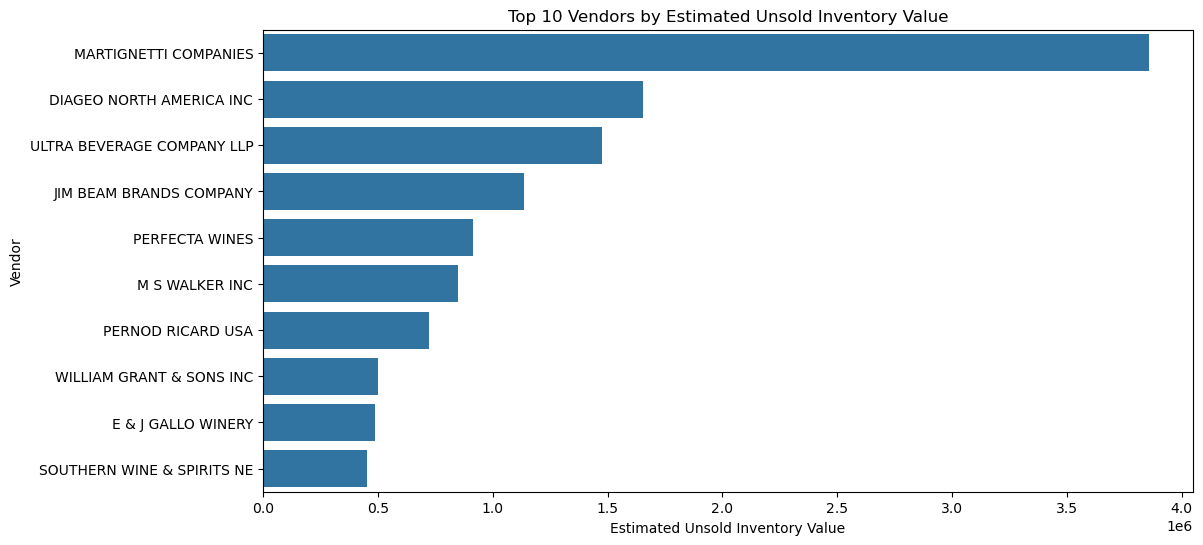

In [79]:
top_unsold_vendors = vendor_unsold_value.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_unsold_vendors,
    x="EstimatedUnsoldValue",
    y="VendorName"
)

plt.title("Top 10 Vendors by Estimated Unsold Inventory Value")
plt.xlabel("Estimated Unsold Inventory Value")
plt.ylabel("Vendor")

plt.show()

In [81]:
# Divide vendors into top and low sales group 
top_threshold=df["TotalSalesDollars"].quantile(0.75)
low_threshold=df["TotalSalesDollars"].quantile(0.25)

print("Top Sales Threshold: ",top_threshold)
print("Low Sales Threshold: ", low_threshold)

Top Sales Threshold:  26505.12
Low Sales Threshold:  782.13


In [84]:
# Seperate Top and Low Sales Group
top_vendors=df[df["TotalSalesDollars"]>=top_threshold]["ProfitMargin"].dropna()
low_vendors=df[df["TotalSalesDollars"]<=low_threshold]["ProfitMargin"].dropna()
print("Top Group Records: ", len(top_vendors))
print("Low Group Records: ", len(low_vendors))

Top Group Records:  3124
Low Group Records:  3124
